# Practical 7: Sequence-Aware Recommendation Using RNN

## Aim

To build a sequence-aware recommender system on MovieLens Small using a **SimpleRNN** and evaluate **next-item prediction** performance.

The model learns:

$
P(i_{t+1} \mid i_1, i_2, \ldots, i_t)
$

The practical uses:

- chronological user interaction sequences
- movie-token vocabulary
- sequence truncation and padding
- embedding layer
- SimpleRNN
- softmax next-item prediction
- Top-1 Accuracy, Hit Rate@5, Hit Rate@10, MRR@10, NDCG@10

In [1]:
from google.colab import drive; drive.mount("/content/drive")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

DATA_FOLDER = "/content/drive/MyDrive/mlsmall"
MAX_SEQ_LEN, EMBEDDING_DIM, RNN_UNITS = 10, 64, 64
BATCH_SIZE, EPOCHS = 128, 10
TOP_N, K1, K2 = 10, 5, 10            # list size, Hit@K1, Hit@K2
DEMO_USER_ID = 25

np.random.seed(42); tf.random.set_seed(42)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load MovieLens Small and sort interactions chronologically

In [2]:
ratings = pd.read_csv(f"{DATA_FOLDER}/ratings.csv")
movies  = pd.read_csv(f"{DATA_FOLDER}/movies.csv")
print("Ratings shape:", ratings.shape, "| Movies shape:", movies.shape)
print("Users:", ratings.userId.nunique(), "| Movies:", ratings.movieId.nunique(), "| Ratings:", len(ratings))
display(ratings.head(), movies.head())

ratings_sorted = ratings.sort_values(["userId", "timestamp"]).reset_index(drop=True)
print("\nChronologically sorted interactions:")
display(ratings_sorted.head(10))

Ratings shape: (100836, 4) | Movies shape: (9742, 3)
Users: 610 | Movies: 9724 | Ratings: 100836


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



Chronologically sorted interactions:


,userId,movieId,rating,timestamp
0,1,804,4.0,964980499
1,1,1210,5.0,964980499
2,1,2018,5.0,964980523
3,1,2628,4.0,964980523
4,1,2826,4.0,964980523
5,1,3578,5.0,964980668
6,1,3617,4.0,964980683
7,1,3744,4.0,964980694
8,1,101,5.0,964980868
9,1,441,4.0,964980868


## 2. Movie vocabulary
Token 0 is reserved for padding; real movies start from token 1.

In [3]:
movie_ids = np.sort(ratings_sorted.movieId.unique())
movie_to_token = {m: t for t, m in enumerate(movie_ids, start=1)}
token_to_movie = {t: m for m, t in movie_to_token.items()}
NUM_ITEMS = len(movie_ids)
VOCAB_SIZE = NUM_ITEMS + 1

titles = movies.drop_duplicates("movieId").set_index("movieId")["title"]
title_of = lambda tok: titles.get(token_to_movie[int(tok)], str(token_to_movie[int(tok)]))

print("Number of modeled movies:", NUM_ITEMS)
print("Vocabulary size including padding:", VOCAB_SIZE)

Number of modeled movies: 9724
Vocabulary size including padding: 9725


## 3. Chronological user sequences (users with ≥ 3 interactions)
Earlier interactions → training, second-last → validation target, last → test target.

In [4]:
user_sequences = {u: g.movieId.map(movie_to_token).tolist() for u, g in ratings_sorted.groupby("userId")}
print("Number of user sequences:", len(user_sequences))
user_sequences = {u: s for u, s in user_sequences.items() if len(s) >= 3}
print("Users with at least 3 interactions:", len(user_sequences))

Number of user sequences: 610
Users with at least 3 interactions: 610


## 4. Example of one user's temporal split

In [5]:
if DEMO_USER_ID not in user_sequences:
    DEMO_USER_ID = next(iter(user_sequences))
demo_seq = user_sequences[DEMO_USER_ID]

print("EXAMPLE TEMPORAL SPLIT - demo user:", DEMO_USER_ID)
for name, toks in [("Training portion", demo_seq[:-2]), ("Validation target", [demo_seq[-2]]), ("Test target", [demo_seq[-1]])]:
    print(f"\n{name}:")
    for t in toks:
        print(" ->", title_of(t))

EXAMPLE TEMPORAL SPLIT - demo user: 25

Training portion:
 -> Lord of the Rings: The Return of the King, The (2003)
 -> Lord of the Rings: The Two Towers, The (2002)
 -> Lord of the Rings: The Fellowship of the Ring, The (2001)
 -> Matrix, The (1999)
 -> Inception (2010)
 -> Star Wars: Episode IV - A New Hope (1977)
 -> Schindler's List (1993)
 -> Dumb & Dumber (Dumb and Dumber) (1994)
 -> Avengers: Infinity War - Part I (2018)
 -> Blade Runner 2049 (2017)
 -> Incredibles 2 (2018)
 -> Wonder (2017)
 -> Up (2009)
 -> Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
 -> Gladiator (2000)
 -> Dark Knight Rises, The (2012)
 -> Thor: Ragnarok (2017)
 -> Saving Private Ryan (1998)
 -> The Imitation Game (2014)
 -> Inglourious Basterds (2009)
 -> Iron Man (2008)
 -> WALL·E (2008)
 -> Dark Knight, The (2008)
 -> Shutter Island (2010)

Validation target:
 -> Three Billboards Outside Ebbing, Missouri (2017)

Test target:
 -> Deadpool 2 (2018)


## 5. Training, validation and test examples

**Prefix training:** every prefix of a user's training portion predicts the next item.

```
[A]       -> B
[A, B]    -> C
[A, B, C] -> D
```

Only the most recent `MAX_SEQ_LEN` tokens are kept, and sequences are **pre-padded** with 0: `[A, B, C]` becomes `[0, 0, ..., A, B, C]`.

In [6]:
pad = lambda seqs: pad_sequences(seqs, maxlen=MAX_SEQ_LEN, padding="pre", truncating="pre", value=0)

train_seqs, y_train = [], []
for s in user_sequences.values():
    tr = s[:-2]
    for end in range(1, len(tr)):
        train_seqs.append(tr[:end][-MAX_SEQ_LEN:]); y_train.append(tr[end])
X_train, y_train = pad(train_seqs), np.array(y_train, dtype=np.int32)

seqs = list(user_sequences.values())
X_val  = pad([s[:-2][-MAX_SEQ_LEN:] for s in seqs])         # context: all but last two -> target: second-last
y_val  = np.array([s[-2] for s in seqs], dtype=np.int32)

test_users     = list(user_sequences)
test_histories = [s[:-1] for s in seqs]                     # context: all but last -> target: last
X_test = pad([h[-MAX_SEQ_LEN:] for h in test_histories])
y_test = np.array([s[-1] for s in seqs], dtype=np.int32)

print("Training examples:", len(y_train), "| X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Validation examples:", len(y_val), "| Test examples:", len(y_test))

Training examples: 99006 | X_train: (99006, 10) | y_train: (99006,)
Validation examples: 610 | Test examples: 610


## 6. SimpleRNN model

```
movie token → Embedding → SimpleRNN → Dense + Softmax → probability of every possible next movie
```

In [7]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
    SimpleRNN(RNN_UNITS),
    Dense(VOCAB_SIZE, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["sparse_categorical_accuracy"])

print("RNN MODEL")
model.summary()

RNN MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 7. Train and plot loss

Epoch 1/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - loss: 8.1500 - sparse_categorical_accuracy: 0.0025 - val_loss: 8.0460 - val_sparse_categorical_accuracy: 0.0066
Epoch 2/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 42s 29ms/step - loss: 7.8107 - sparse_categorical_accuracy: 0.0026 - val_loss: 8.0156 - val_sparse_categorical_accuracy: 0.0049
Epoch 3/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - loss: 7.6581 - sparse_categorical_accuracy: 0.0036 - val_loss: 7.9827 - val_sparse_categorical_accuracy: 0.0049
Epoch 4/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - loss: 7.4623 - sparse_categorical_accuracy: 0.0057 - val_loss: 7.8565 - val_sparse_categorical_accuracy: 0.0000e+00
Epoch 5/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 42s 28ms/step - loss: 7.2469 - sparse_categorical_accuracy: 0.0080 - val_loss: 7.8148 - val_sparse_categorical_accuracy: 0.0033
Epoch 6/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 7.0672 - sparse_categorical_accuracy: 0.0107 - val_loss: 7.8268 - val_sparse_categorical_accur

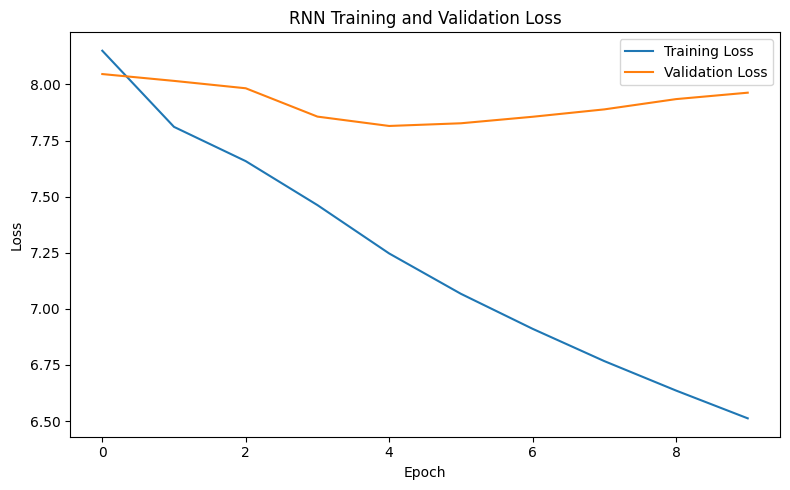

In [8]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("RNN Training and Validation Loss")
plt.legend(); plt.tight_layout(); plt.show()

## 8. Top-N next-item prediction for one user
Padding and already-seen movies are masked before ranking.

TOP 10 NEXT-ITEM PREDICTIONS FOR USER 25


,Rank,movieId,Movie,Probability
0,1,356,Forrest Gump (1994),0.014142
1,2,122886,Star Wars: Episode VII - The Force Awakens (2015),0.012045
2,3,33794,Batman Begins (2005),0.011287
3,4,48780,"Prestige, The (2006)",0.011143
4,5,89745,"Avengers, The (2012)",0.010888
5,6,48516,"Departed, The (2006)",0.010287
6,7,99114,Django Unchained (2012),0.009651
7,8,109487,Interstellar (2014),0.009403
8,9,47,Seven (a.k.a. Se7en) (1995),0.009274
9,10,115617,Big Hero 6 (2014),0.008853



Actual next movie: Deadpool 2 (2018)


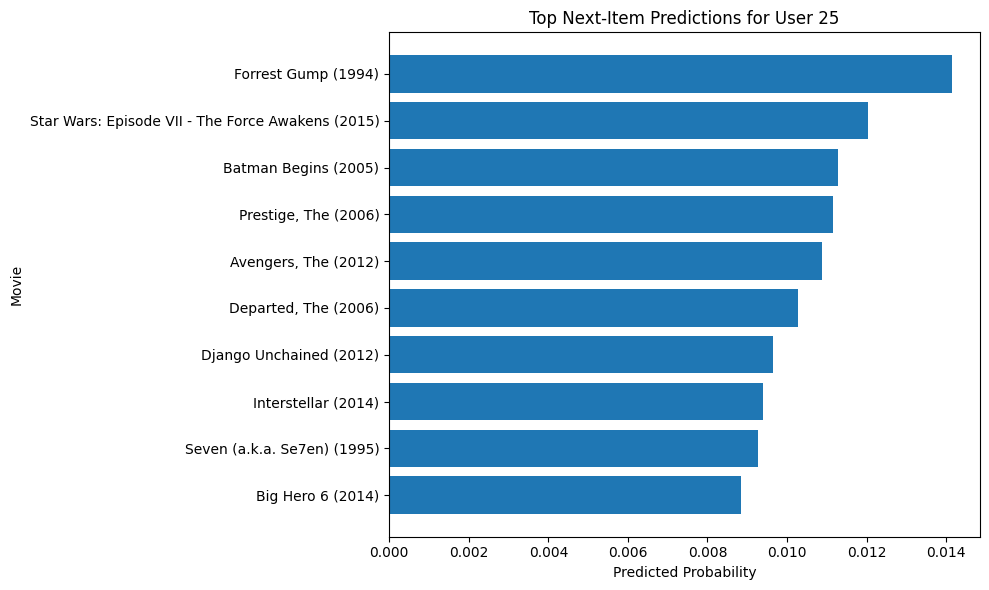

In [9]:
def predict_next_items(history, top_n=TOP_N):
    probs = model.predict(pad([history[-MAX_SEQ_LEN:]]), verbose=0)[0]
    probs[0] = -np.inf                       # padding is never a recommendation
    probs[np.unique(history)] = -np.inf      # remove movies already seen
    top = np.argsort(-probs)[:top_n]
    return pd.DataFrame({"Rank": range(1, len(top) + 1), "movieId": [token_to_movie[int(t)] for t in top],
                         "Movie": [title_of(t) for t in top], "Probability": probs[top]})

demo_pred = predict_next_items(demo_seq[:-1])
print(f"TOP {TOP_N} NEXT-ITEM PREDICTIONS FOR USER {DEMO_USER_ID}")
display(demo_pred)
print("\nActual next movie:", title_of(demo_seq[-1]))

d = demo_pred.sort_values("Probability")
plt.figure(figsize=(10, 6)); plt.barh(d["Movie"], d["Probability"])
plt.xlabel("Predicted Probability"); plt.ylabel("Movie"); plt.title(f"Top Next-Item Predictions for User {DEMO_USER_ID}")
plt.tight_layout(); plt.show()

## 9. Evaluate next-item prediction on all test users
Rank of the true next item among unseen movies → Top-1 Accuracy, HR@5, HR@10, MRR@10, NDCG@10.

In [10]:
test_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)

ranks = []
for p, target, h in zip(test_probs, y_test, test_histories):
    p = p.copy(); p[0] = -np.inf; p[np.unique(h)] = -np.inf
    ranks.append(int(np.sum(p > p[target])) + 1 if np.isfinite(p[target]) else np.nan)
r = pd.Series(ranks, dtype=float)

results = pd.DataFrame({
    "userId": test_users, "Target Movie": [title_of(t) for t in y_test], "Rank": r,
    "Top-1 Correct": (r == 1).astype(int), f"Hit@{K1}": (r <= K1).astype(int), f"Hit@{K2}": (r <= K2).astype(int),
    f"RR@{K2}": np.where(r <= K2, 1 / r, 0.0), f"NDCG@{K2}": np.where(r <= K2, 1 / np.log2(r + 1), 0.0)})

metric_table = pd.DataFrame({
    "Metric": ["Top-1 Accuracy", f"Hit Rate@{K1}", f"Hit Rate@{K2}", f"MRR@{K2}", f"NDCG@{K2}"],
    "Value": results[["Top-1 Correct", f"Hit@{K1}", f"Hit@{K2}", f"RR@{K2}", f"NDCG@{K2}"]].mean().values})

print("NEXT-ITEM PREDICTION EVALUATION")
display(metric_table)
print("\nSample test results")
display(results.head(15))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step 
NEXT-ITEM PREDICTION EVALUATION


,Metric,Value
0,Top-1 Accuracy,0.009836
1,Hit Rate@5,0.027869
2,Hit Rate@10,0.044262
3,MRR@10,0.018777
4,NDCG@10,0.024743



Sample test results


,userId,Target Movie,Rank,Top-1 Correct,Hit@5,Hit@10,RR@10,NDCG@10
0,1,20 Dates (1998),3336.0,0,0,0,0.0,0.0
1,2,"Town, The (2010)",521.0,0,0,0,0.0,0.0
2,3,You've Got Mail (1998),281.0,0,0,0,0.0,0.0
3,4,Bridget Jones's Diary (2001),114.0,0,0,0,0.0,0.0
4,5,In the Line of Fire (1993),25.0,0,0,0,0.0,0.0
5,6,Independence Day (a.k.a. ID4) (1996),5411.0,0,0,0,0.0,0.0
6,7,"Holiday, The (2006)",1443.0,0,0,0,0.0,0.0
7,8,Ed Wood (1994),22.0,0,0,0,0.0,0.0
8,9,Body of Evidence (1993),9392.0,0,0,0,0.0,0.0
9,10,Dirty Dancing (1987),1104.0,0,0,0,0.0,0.0


## 10. Visualise rank distribution and metrics

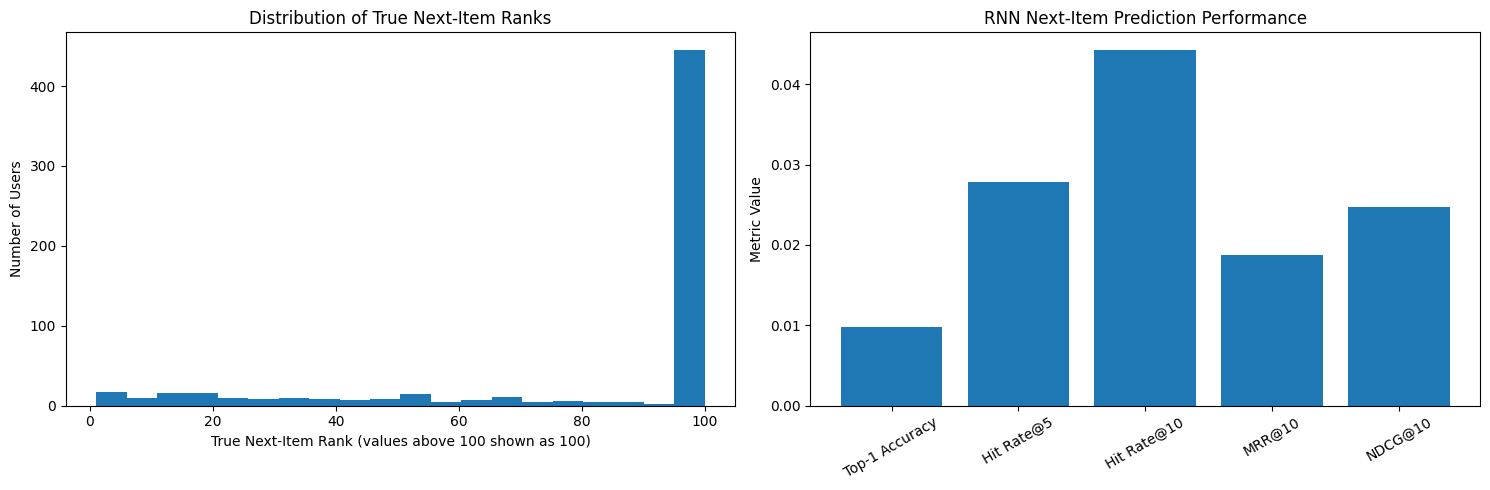

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(np.minimum(r.dropna(), 100), bins=20)          # ranks above 100 shown as 100
ax[0].set(xlabel="True Next-Item Rank (values above 100 shown as 100)", ylabel="Number of Users",
          title="Distribution of True Next-Item Ranks")

ax[1].bar(metric_table["Metric"], metric_table["Value"])
ax[1].set(ylabel="Metric Value", title="RNN Next-Item Prediction Performance")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout(); plt.show()